Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 861, 16)        │            48 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 430, 16)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 430, 16)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 429, 32)        │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 214, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 214, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 213, 64)        │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_2 (MaxPooling1D)  │ (None, 106, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 106, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_3 (Conv1D)               │ (None, 105, 128)       │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_3 (MaxPooling1D)  │ (None, 52, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 52, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,776 (85.06 KB)

 Trainable params: 21,776 (85.06 KB)

 Non-trainable params: 0 (0.00 B)

23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
[0]	validation_0-mlogloss:1.68876
[1]	validation_0-mlogloss:1.59836
[2]	validation_0-mlogloss:1.51755
[3]	validation_0-mlogloss:1.44758
[4]	validation_0-mlogloss:1.38392
[5]	validation_0-mlogloss:1.32653
[6]	validation_0-mlogloss:1.27215
[7]	validation_0-mlogloss:1.22465
[8]	validation_0-mlogloss:1.17966
[9]	validation_0-mlogloss:1.13909
[10]	validation_0-mlogloss:1.10127
[11]	validation_0-mlogloss:1.06633
[12]	validation_0-mlogloss:1.03359
[13]	validation_0-mlogloss:1.00324
[14]	validation_0-mlogloss:0.97493
[15]	validation_0-mlogloss:0.94821
[16]	validation_0-mlogloss:0.92331
[17]	validation_0-mlogloss:0.90012
[18]	validation_0-mlogloss:0.87837
[19]	validation_0-mlogloss:0.85779
[20]	validation_0-mlogloss:0.83889
[21]	validation_0-mlogloss:0.82178
[22]	validation_0-mlogloss:0.80539
[23]	validation_0-mlogloss:0.78934
[24]	validation_0-mlogloss:0.77409
[25]	validation_0-mlogloss:0.76013
[26]	validation_0-mlogl

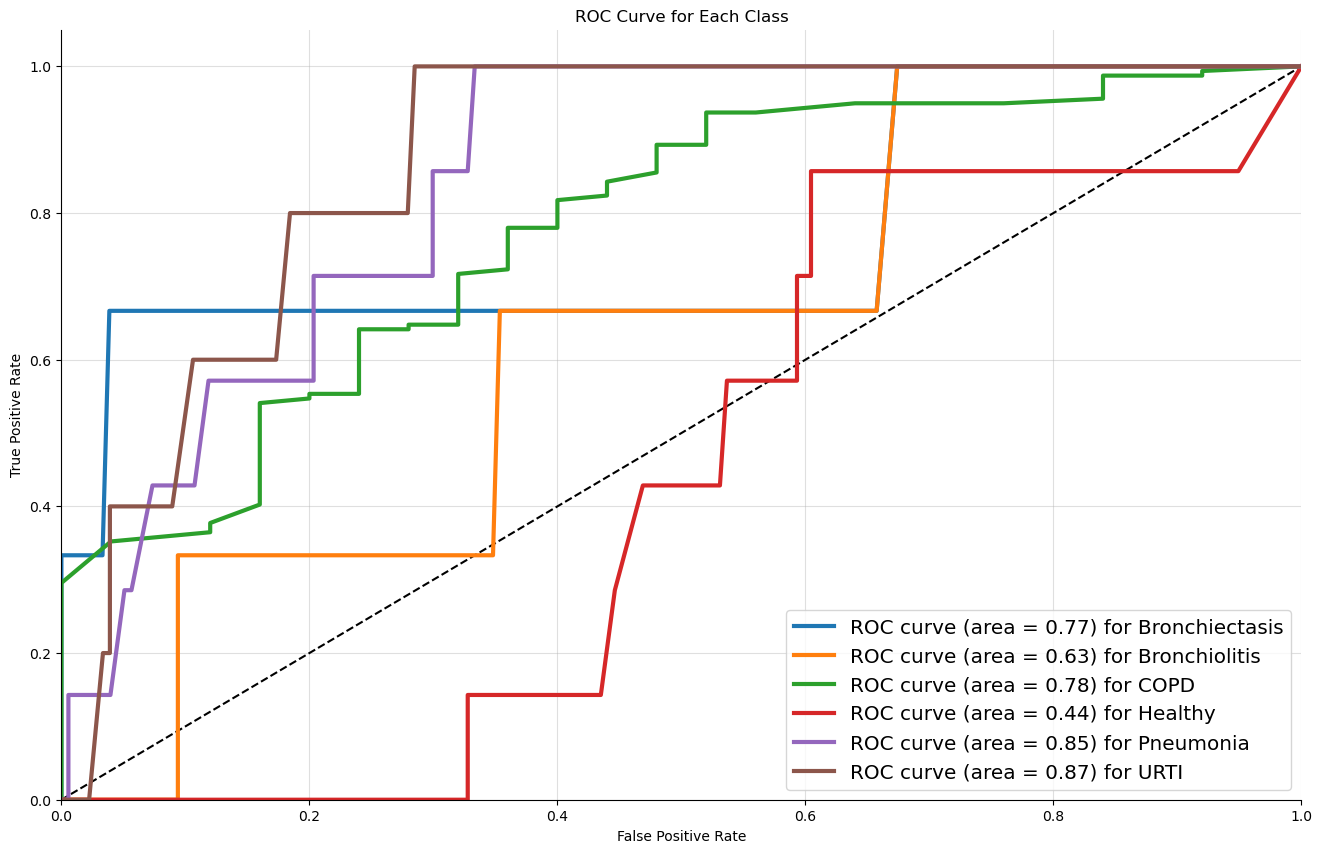

In [1]:
import xgboost as xgb
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import numpy as np
from datetime import datetime
from os import listdir
from os.path import isfile, join
import librosa
import numpy as np
import pandas as pd
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Conv1D, MaxPooling1D, GlobalAveragePooling1D, Input
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import ModelCheckpoint
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
import xgboost as xgb
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns

# File paths and loading data
mypath = "E:\\FFF\\respiratory-sound-database\\Respiratory_Sound_Database\\Respiratory_Sound_Database\\audio_and_txt_files\\"
filenames = [f for f in listdir(mypath) if (isfile(join(mypath, f)) and f.endswith('.wav'))]
p_id_in_file = [int(name[:3]) for name in filenames]
p_id_in_file = np.array(p_id_in_file)
max_pad_len = 862

# Feature extraction function (Spectral Bandwidth + Energy)
def extract_features(file_name):
    try:
        audio, sample_rate = librosa.load(file_name, res_type='kaiser_fast', duration=20)
        
        # Extract Spectral Bandwidth
        spectral_bandwidth = librosa.feature.spectral_bandwidth(y=audio, sr=sample_rate)
        spectral_bandwidth_mean = np.mean(spectral_bandwidth, axis=1)
        
        # Extract Energy (Root Mean Square Energy)
        energy = librosa.feature.rms(y=audio)
        energy_mean = np.mean(energy, axis=1)
        
        # Combine features
        features = np.hstack([spectral_bandwidth_mean, energy_mean])
        
        # Pad features to ensure consistent length
        pad_width = max_pad_len - features.shape[0]
        features = np.pad(features, pad_width=(0, pad_width), mode='constant')
    except Exception as e:
        print(f"Error encountered while parsing file: {file_name}")
        print(f"Exception: {e}")
        return None 
    return features

filepaths = [join(mypath, f) for f in filenames]
p_diag = pd.read_csv("E:\\FFF\\respiratory-sound-database\\Respiratory_Sound_Database\\Respiratory_Sound_Database\\patient_diagnosis.csv", header=None)
labels = np.array([p_diag[p_diag[0] == x][1].values[0] for x in p_id_in_file])
features = [extract_features(file_name) for file_name in filepaths]
features = np.array(features)

# Removing specific labels and converting labels
features1 = np.delete(features, np.where((labels == 'Asthma') | (labels == 'LRTI'))[0], axis=0)
labels1 = np.delete(labels, np.where((labels == 'Asthma') | (labels == 'LRTI'))[0], axis=0)

# One-hot encode labels
le = LabelEncoder()
i_labels = le.fit_transform(labels1)
oh_labels = to_categorical(i_labels)

# Reshape features for CNN (1D input)
features1 = np.reshape(features1, (*features1.shape, 1))  # Shape: (num_samples, max_pad_len, 1)

# Train-test split
x_train, x_test, y_train, y_test = train_test_split(features1, oh_labels, stratify=oh_labels, test_size=0.2, random_state=42)

# Define CNN model for feature extraction (1D CNN)
num_columns = max_pad_len
num_channels = 1
filter_size = 2

cnn_model = Sequential()
cnn_model.add(Input(shape=(num_columns, num_channels)))  # Input shape: (max_pad_len, 1)
cnn_model.add(Conv1D(filters=16, kernel_size=filter_size, activation='relu'))
cnn_model.add(MaxPooling1D(pool_size=2))
cnn_model.add(Dropout(0.2))
cnn_model.add(Conv1D(filters=32, kernel_size=filter_size, activation='relu'))
cnn_model.add(MaxPooling1D(pool_size=2))
cnn_model.add(Dropout(0.2))
cnn_model.add(Conv1D(filters=64, kernel_size=filter_size, activation='relu'))
cnn_model.add(MaxPooling1D(pool_size=2))
cnn_model.add(Dropout(0.2))
cnn_model.add(Conv1D(filters=128, kernel_size=filter_size, activation='relu'))
cnn_model.add(MaxPooling1D(pool_size=2))
cnn_model.add(Dropout(0.2))
cnn_model.add(GlobalAveragePooling1D())

cnn_model.compile(loss='categorical_crossentropy', metrics=['accuracy'], optimizer='adam')
cnn_model.summary()

# Extract features using CNN
x_train_features = cnn_model.predict(x_train)
x_test_features = cnn_model.predict(x_test)

# Flatten the features for XGBoost
x_train_features = x_train_features.reshape(x_train_features.shape[0], -1)
x_test_features = x_test_features.reshape(x_test_features.shape[0], -1)

# Convert one-hot labels to single integers for XGBoost
y_train = np.argmax(y_train, axis=1)
y_test = np.argmax(y_test, axis=1)

# Handle class imbalance by assigning class weights (scale_pos_weight) in XGBoost
class_weights = {i: 1.0 for i in range(len(le.classes_))}  # Default weights for each class
class_weights[1] = 10  # Example, increase weight for class 1 (Bronchiolitis)
class_weights[3] = 2   # Example, increase weight for class 3 (Healthy)
class_weights[4] = 3   # Example, increase weight for class 4 (Pneumonia)

# XGBoost model with adjusted hyperparameters and class weights
xgb_model = xgb.XGBClassifier(
    n_estimators=200,  # Increase number of trees
    max_depth=6,       # Deeper trees
    learning_rate=0.05,  # Lower learning rate
    subsample=0.9,     # Use 90% of data for training each tree
    colsample_bytree=0.8,  # Fraction of features used per tree
    gamma=0.1,        # Regularization parameter
    use_label_encoder=False,
    eval_metric='mlogloss',
    early_stopping_rounds=10  # Specify early_stopping_rounds here
)

# Train the XGBoost model
xgb_model.fit(
    x_train_features, y_train,
    eval_set=[(x_test_features, y_test)],  # Evaluation set for early stopping
    verbose=True
)

# Evaluate model
y_pred = xgb_model.predict(x_test_features)
accuracy = accuracy_score(y_test, y_pred)
print(f"XGBoost Test Accuracy: {accuracy:.4f}")

# Evaluating the model on the training set
y_train_pred = xgb_model.predict(x_train_features)
train_accuracy = accuracy_score(y_train, y_train_pred)
print(f"XGBoost Training Accuracy: {train_accuracy:.4f}")

# Evaluating the model on the testing set
y_test_pred = xgb_model.predict(x_test_features)
test_accuracy = accuracy_score(y_test, y_test_pred)
print(f"XGBoost Testing Accuracy: {test_accuracy:.4f}")

# Confusion matrix and classification report
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=le.classes_, zero_division=1))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

# Plot ROC curves
fpr = dict()
tpr = dict()
roc_auc = dict()
y_test_onehot = to_categorical(y_test, num_classes=len(le.classes_))
y_pred_proba = xgb_model.predict_proba(x_test_features)
for i in range(len(le.classes_)):
    fpr[i], tpr[i], _ = roc_curve(y_test_onehot[:, i], y_pred_proba[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# ROC Curve Plot
fig, ax = plt.subplots(figsize=(16, 10))
ax.plot([0, 1], [0, 1], 'k--')
ax.set_xlim([0.0, 1.0])
ax.set_ylim([0.0, 1.05])
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curve for Each Class')
for i in range(len(le.classes_)):
    ax.plot(fpr[i], tpr[i], linewidth=3, label='ROC curve (area = %0.2f) for %s' % (roc_auc[i], le.classes_[i]))
ax.legend(loc="best", fontsize='x-large')
ax.grid(alpha=.4)
sns.despine()
plt.show()